In [1]:
from sound_simulation import *
from beamforming import *
from sensor_array import *
from scene import *
from util import *
from psd_estimation import *
from plot_utils import *
from cropac import *

import numpy as np
import matplotlib.pyplot as plt

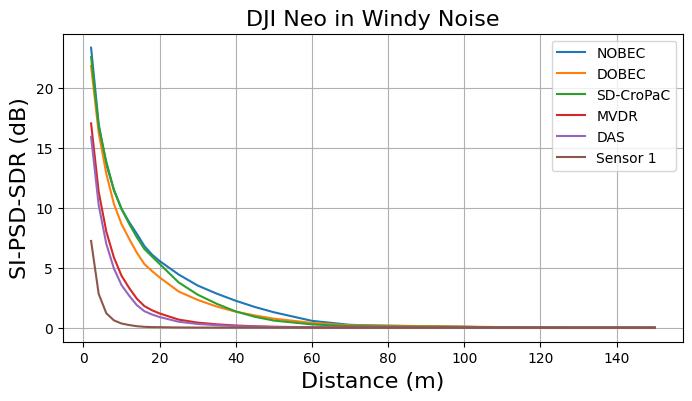

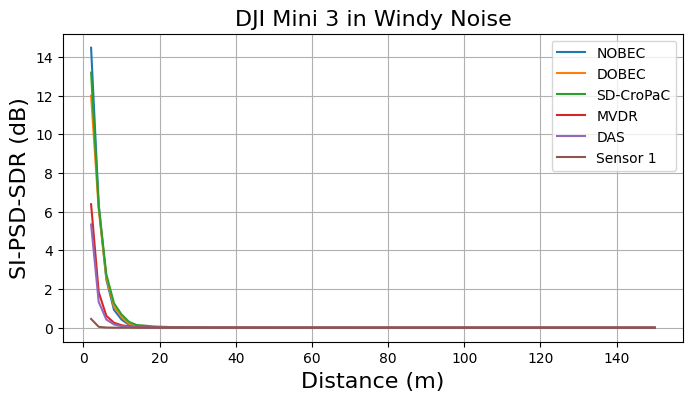

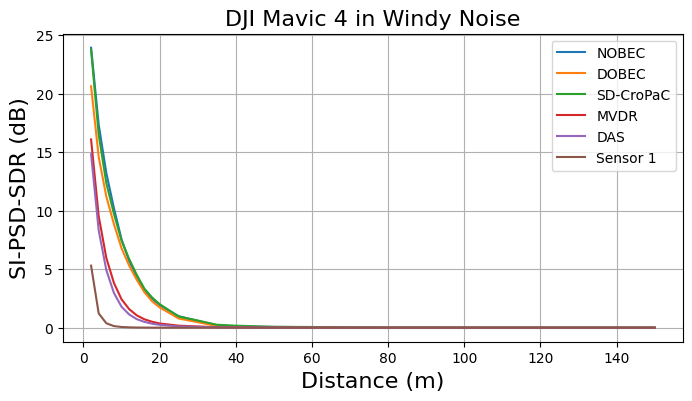

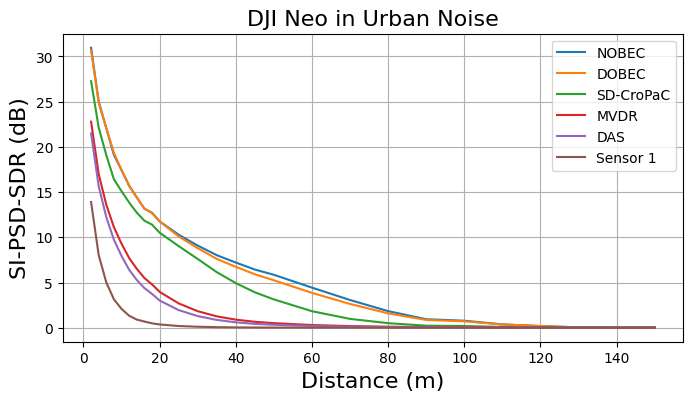

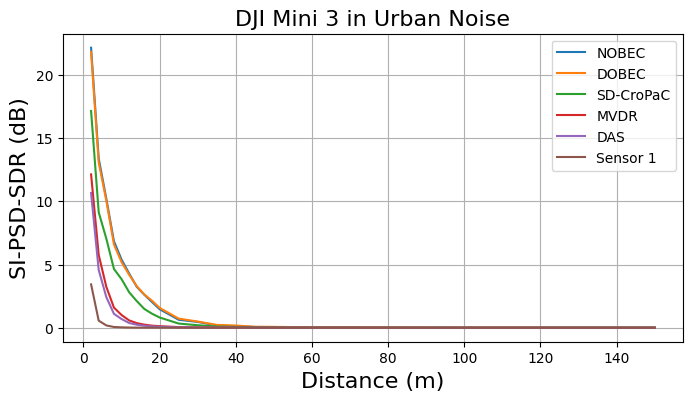

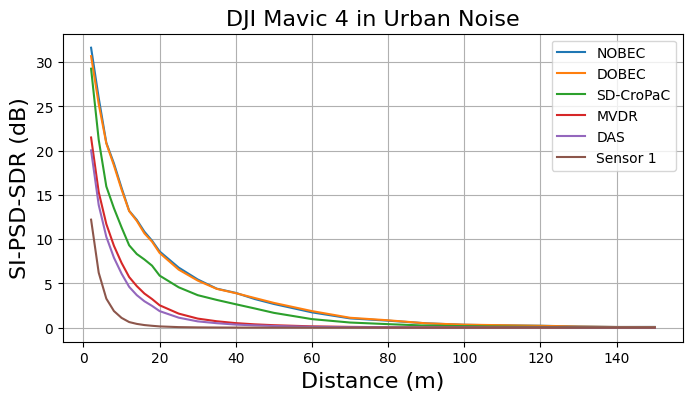

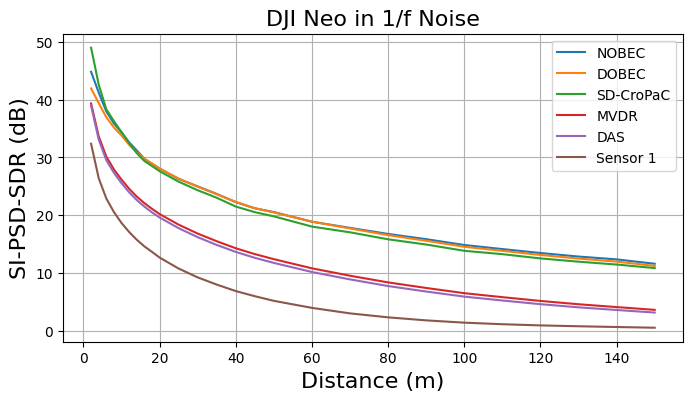

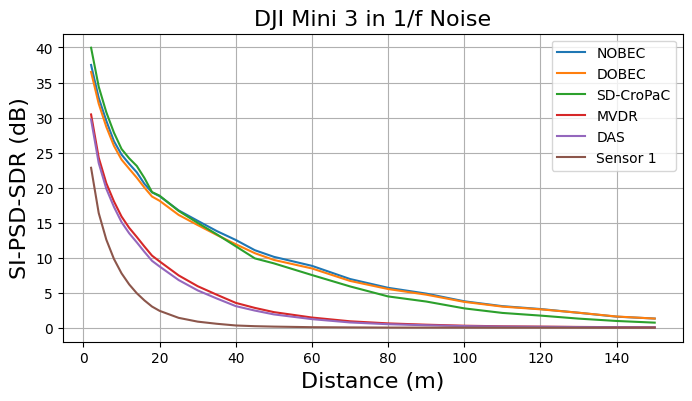

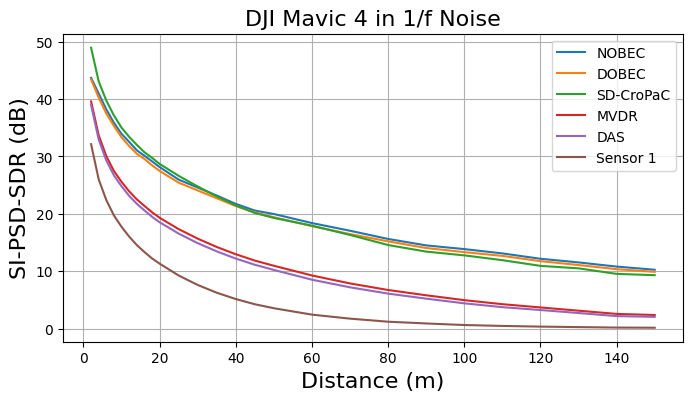

In [8]:
fig_width = 8

duration = 2
sr = 48000
c = 344
fmin = 750
fmax = 6000

N = 2**10
step = N//2
window = np.hanning(N)**0.5
VN, f, validf = valid_frequency_bins(fmin, fmax, N, sr)
k = 2 * np.pi * f / c

sensor_array = array_circle8()

noise_audios = [
    normalize_channels(prepare_audio("../samples/meas2_ambience.wav", duration, sr, False)),
    normalize_channels(prepare_audio("../samples/meas1_ambience.wav", duration, sr, False)),
    pink_diffuse_noise(duration * sr, sensor_array.positions, sr)]
noise_spl = [64, 60, 60]
noise_name = ["Windy Noise", "Urban Noise", "1/f Noise"]

target_distances = np.concat([range(2, 20, 2), range(20, 50, 5), range(50, 151, 10)])
target_positions = [np.array([i, 0, 0]) for i in target_distances]

drone_audios = ["../samples/neo_steady.wav", "../samples/mini3_steady.wav", "../samples/mavic4_steady.wav"]
drone_spl = [65, 58, 68]
drone_name = ["DJI Neo", "DJI Mini 3", "DJI Mavic 4"]

ch0_estimator = CH0_PSDE()
das_estimator = DAS_PSDE()
mvdr_estimator = MVDR_PSDE(db2lin(10))
cropac_estimator = CroPaC_PSDE(0)
dobec_estimator = DOBEC_PSDE(0, order = 2)
nobec_estimator = NOBEC_PSDE(db2lin(10), 0, order = 2)

estimators = [
    ["NOBEC", nobec_estimator],
    ["DOBEC", dobec_estimator],
    ["SD-CroPaC", cropac_estimator],
    ["MVDR", mvdr_estimator],
    ["DAS", das_estimator],
    ["Sensor 1", ch0_estimator],
]

NN = len(noise_audios)
ND = len(drone_audios)
NP = len(target_positions)
NE = len(estimators)

for ni in range(NN):

    SN, tidx, noise_snaps = stft(noise_audios[ni], window, step, validf)
    Sn = np.array([compute_covariance_matrices(snap) for snap in noise_snaps])
    Sn = fb_average(Sn, sensor_array.positions)
    Sn = time_average(Sn, smoothing_alpha(sr*0.1, step, 0.5))

    for di in range(ND):

        results = []

        for ip in range(NP):

            target_position = target_positions[ip]
            scene = scene_stationary(duration, sr, target_position)
            target_gain = db2lin(drone_spl[di]-noise_spl[ni])
            target_sound = prepare_drone_audio(scene, sensor_array, drone_audios[di], duration, sr, target_gain)
            audio = noise_audios[ni] + target_sound

            _, _, snaps = stft(audio, window, step, validf)
            _, _, target_snaps = stft(target_sound, window, step, validf)
            target_udir = target_position / np.linalg.norm(target_position)
            target_steer = create_steering_vectors(create_distance_vectors(target_udir[None,:], sensor_array.positions), k[:,None])

            Sx = np.array([compute_covariance_matrices(snap) for snap in snaps])
            Sx = fb_average(Sx, sensor_array.positions)
            Sx = time_average(Sx, smoothing_alpha(sr*0.1, step, 0.5))
            
            St = np.array([compute_covariance_matrices(snap) for snap in target_snaps])
            St = fb_average(St, sensor_array.positions)
            St = time_average(St, smoothing_alpha(sr*0.1, step, 0.5))

            target_psd = np.array([ch0_estimator.estimate_psd(S) for S in St])

            params = PSDEParams(
                sensor_array.positions,
                target_udir, k,
                target_steer,
                compute_covariance_matrices(snaps[0]))

            noise_psds = []
            for ei in range(NE):
                estimate = []
                for S in Sn:
                    params.covariance_matrices = S
                    estimators[ei][1].update_parameters(params)
                    estimate.append(estimators[ei][1].estimate_psd(S))
                noise_psds.append(np.array(estimate))

            sisdr_estimates = []
            for ei in range(NE):
                estimate = []
                for S in Sx:
                    params.covariance_matrices = S
                    estimators[ei][1].update_parameters(params)
                    estimate.append(estimators[ei][1].estimate_psd(S))
                estimate = np.array(estimate)
                sisdr_estimates.append(si_psd_sdr(noise_psds[ei][-SN//2:], target_psd[-SN//2:], estimate[-SN//2:]))

            results.append(sisdr_estimates)

        results = np.array(results).T

        fig = plt.figure(figsize=(fig_width, fig_width*0.5))
        ax = fig.add_subplot(111)

        for ei in range(NE):
            ax.plot(target_distances, results[ei], label=estimators[ei][0])

        ax.set_title(f"{drone_name[di]} in {noise_name[ni]}", fontsize=16)
        ax.set_ylabel("SI-PSD-SDR (dB)", fontsize=16)
        ax.set_xlabel("Distance (m)", fontsize=16)
        ax.grid()
        ax.legend(loc='upper right')
        plt.show()
